[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TheBestProEver/100micron-sim/blob/main/notebooks/06_the_3d_simulation.ipynb)

# 06 · The 3-D simulation: grains and rigid clumps in a tubule

**The question.** Notebooks 01-03 follow ONE impact along a line. In a DOLL-E tubule a hundred grains fly in every
direction, hit each other at all angles, stick into clumps that spin, and end on the walls. How does the readable
core simulate that in 3-D, why can it still use the 1-D impact model, and why do momentum and angular momentum come
out exactly right?

**After this notebook you can explain**
- how the exact moment of the next collision is found (a quadratic equation, not small time steps);
- why each impact is decided by the 1-D model of notebook 01, with an *effective mass*, and the checks that show this
  is enough;
- how two grains that stick become one rigid clump, and why linear and angular momentum stay exact (to round-off);
- how a clump rotates between impacts;
- what the rigid-clump simulation leaves out compared with the full simulator, and how much each part matters;
- what happens in two tubules, one silica and one graphite, started identically: which one clumps more.

**The code.** `dolle_core/clumps.py` (rigid clumps), `dolle_core/impacts.py` (one impact), `dolle_core/sim3d.py`
(the tubule and the event loop), `dolle_core/scenes.py` (the scenes of the web page). Plain python and numpy: the
same files run in the web page's sandbox. Every function says which function of the full simulator's v0.5 chamber
engine (`dolle_sim/simulation.py`) it mirrors.

**Units.** SI unless stated. Plots use mm, µm, mm/s, s.

In [1]:
# Make the repository's packages (dolle_core, dolle_sim, and the optional extras) importable, in Colab or from a clone.
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:   # in Colab: install the repository from GitHub (takes ~30 s)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/TheBestProEver/100micron-sim.git"], check=True)
else:                               # locally: the repository folder is this folder or the one above (notebooks/)
    repo = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "dolle_core").is_dir())
    sys.path.insert(0, str(repo))
    if (repo / "extras").is_dir():  # the optional v0.6 engine (extras/dolle_extras), used by the 3-D cells
        sys.path.insert(1, str(repo / "extras"))

In [2]:
import math, time
import numpy as np
import matplotlib.pyplot as plt
import dolle_core as dc                          # the readable core of the DOLL-E simulator
from dolle_core import clumps as cl, impacts, sim3d, scenes
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
R = 50e-6                                        # grain radius used in the examples [m]
QUIET = sim3d.Tubule(accel=(0.0, 0.0, 0.0))      # the DOLL-E tubule with the residual acceleration switched off
c0 = np.asarray(QUIET.size) / 2                  # its centre [m]

## 1. What is simulated

The **tubule** is a box $0 \le x \le 12.7$ mm, $0 \le y \le 12.7$ mm, $0 \le z \le 38.1$ mm (0.5 × 0.5 × 1.5 in,
borosilicate glass, $z$ along the rocket's axis; `configs/mission_quarter_deck.json`). The only force on a flying
grain is the residual acceleration $\mathbf a$ of the payload, $10^{-4}$ g along $+z$ (ASSUMED order of magnitude,
PROVENANCE.md).

Every **grain** $k$ is a sphere: radius $r_k$, mass $m_k = \frac43\pi r_k^3\rho$, own moment of inertia
$I_{0,k} = \frac25 m_k r_k^2$. Every grain belongs to one **clump** $b$: a single grain, or grains that have stuck
together and now move as one rigid body. A clump has

| symbol | meaning | unit |
|---|---|---|
| $M_b$ | mass, the sum of its grains' masses | kg |
| $\mathbf X_b$, $\mathbf V_b$ | centre of mass and its velocity | m, m/s |
| $\mathbf L_b$ | spin angular momentum about $\mathbf X_b$ | kg m²/s |
| $Q_b$ | orientation: rotation from the clump's principal axes to the tubule | - |
| $I_b$ | inertia tensor; $\boldsymbol\omega_b = I_b^{-1}\mathbf L_b$ the angular velocity | kg m², rad/s |

A member grain sits at $\mathbf x_k = \mathbf X_b + \mathbf o_k$, where the offset $\mathbf o_k$ is fixed in the
clump's own frame (that is what *rigid* means), and moves at $\mathbf V_b + \boldsymbol\omega_b\times\mathbf o_k$.
A clump that touches a wall and sticks is **wall-bound**: it stops and stays (`frozen` in the code).

What happens, in time order: clumps fly in straight lines (plus the slow parabola of $\mathbf a$) and spin; the
code finds the next moment two grains of different clumps touch, or a grain touches a wall; it moves everything to
that moment; the 1-D contact model decides stick or bounce; the velocities jump; and the search starts again.

> **Why this choice: impacts as instants, clumps as rigid bodies.**
> - *The time scales.* A contact lasts about 1 µs (section 4; notebook 01). Grains meet each other every ~0.01-0.1 s
>   in a dense cloud and the run lasts 12 s. A simulation that follows the contact forces at every instant (the
>   discrete element method, DEM) needs steps of ~3 ns: about $4\times10^9$ steps for 12 s. Treating each impact as
>   an instant, decided by the contact model of notebook 01, needs one 1-D integration (~1 ms of computer time) per
>   impact. This is the method of the full simulator's v0.5 chamber engine, which produced the flight campaign
>   results; its full-contact engine (v0.6, now in `extras/`) follows the contact forces instead.
> - *Alternatives:* full DEM (exact for contacts that last, e.g. clumps rolling into new shapes; far too slow for
>   12 s in a browser); hard spheres with a fixed restitution (no adhesion: nothing could stick).
> - *Evidence it is enough:* section 4 checks the impact model, section 9 lists everything left out with its size.

In [3]:
# Two grains, the state the code keeps (clumps.py: Clumps). They fly towards each other along x.
sim = sim3d.make_sim(QUIET, "silica", [R, R], [c0 - [3 * R, 0, 0], c0 + [3 * R, 0, 0]],
                     [[5e-3, 0, 0], [-5e-3, 0, 0]])
c = sim.clumps
print("grain -> clump:", c.body, "   grains per clump:", c.n)
print("masses M [kg]:", c.M[:2], "   I0 = 2/5 m r^2 [kg m^2]:", c.I0[:2])
print("X [mm]:", (c.X[:2] * 1e3).round(4).tolist(), "  V [mm/s]:", (c.V[:2] * 1e3).tolist())

grain -> clump: [0 1]    grains per clump: [1 1]
masses M [kg]: [1.04719755e-09 1.04719755e-09]    I0 = 2/5 m r^2 [kg m^2]: [1.04719755e-18 1.04719755e-18]
X [mm]: [[6.2, 6.35, 19.05], [6.5, 6.35, 19.05]]   V [mm/s]: [[5.0, 0.0, 0.0], [-5.0, 0.0, 0.0]]


## 2. Free flight: the time step

One step of length $\Delta t$ = 4 ms (the mission's step) is **velocity Verlet** (kick, drift, kick; Verlet 1967,
Swope et al. 1982), as in the full simulator:

$$\mathbf V \mathrel{+}= \mathbf a\,\tfrac{\Delta t}{2}, \qquad
\text{drift for } \Delta t \text{ (straight lines; impacts resolved on the way)}, \qquad
\mathbf V \mathrel{+}= \mathbf a\,\tfrac{\Delta t}{2}.$$

*Why it is exact for a constant acceleration.* Without impacts the drift moves the centre of mass by
$(\mathbf V_0 + \mathbf a\Delta t/2)\Delta t = \mathbf V_0\Delta t + \frac12\mathbf a\Delta t^2$: exactly the
parabola $\mathbf x(t) = \mathbf x_0 + \mathbf V_0 t + \frac12\mathbf a t^2$ at the end of every step, and the
velocity is exactly $\mathbf V_0 + \mathbf a t$. The acceleration acts at the centre of mass, so it exerts no torque.

*Inside a step* the code searches for collisions along the straight line at the half-step velocity, while the true
path is the parabola. The two differ by $\frac12 a\,t(\Delta t - t)$, largest at $t = \Delta t/2$:

$$\max |\text{parabola} - \text{line}| = \frac{a\,\Delta t^2}{8} = \frac{9.8\times10^{-4}\times(4\times10^{-3})^2}{8}
= 2\times10^{-9}\ \text{m},$$

$4\times10^{-5}$ of a grain radius: no collision can be found at a noticeably wrong place. The matching
velocity error: an impact inside a step uses the half-step velocity, which differs from the true one by at most
$a\,\Delta t/2 = 2\times10^{-6}$ m/s, $3\times10^{-4}$ of silica's 6.2 mm/s sticking speed (printed below).

In [4]:
a = np.array([1e-3, -2e-3, 0.5e-3])                      # a large acceleration in a 2 m box (no walls in reach)
tub = sim3d.Tubule(size=(2.0, 2.0, 2.0), accel=tuple(a))
x0, v0 = np.array([1.0, 1.0, 1.0]), np.array([1e-3, 2e-3, -1e-3])
s = sim3d.make_sim(tub, "silica", [R], [x0], [v0])
sim3d.run(s, 10.0, stop_when_settled=False)               # 2500 steps
exact = x0 + v0 * s.t + 0.5 * a * s.t ** 2
print(f"after {s.steps} steps, t = {s.t} s: |x - parabola| = {np.abs(s.clumps.pos[0] - exact).max():.1e} m")
print(f"largest line-vs-parabola gap inside a 4 ms step at 1e-4 g: {1e-4 * dc.G0 * 4e-3**2 / 8:.1e} m")
v_si = dc.sticking_threshold(dc.make_pair("silica", R, "silica", R))
print(f"largest velocity difference, half-step vs true: a dt/2 = {1e-4 * dc.G0 * 4e-3 / 2:.1e} m/s = "
      f"{1e-4 * dc.G0 * 4e-3 / 2 / v_si:.0e} of silica's sticking speed {v_si * 1e3:.2f} mm/s")

after 2500 steps, t = 10.0 s: |x - parabola| = 2.9e-15 m
largest line-vs-parabola gap inside a 4 ms step at 1e-4 g: 2.0e-09 m
largest velocity difference, half-step vs true: a dt/2 = 2.0e-06 m/s = 3e-04 of silica's sticking speed 6.18 mm/s


## 3. Finding the next collision exactly

**Two grains.** Grains $i$ and $j$ of different clumps, relative position $\mathbf d = \mathbf x_j - \mathbf x_i$
and relative velocity $\mathbf u = \mathbf v_j - \mathbf v_i$. During the drift $\mathbf d(t) = \mathbf d + \mathbf u t$,
and they touch when the centre distance equals $S = r_i + r_j$:

$$|\mathbf d + \mathbf u t|^2 = S^2 \quad\Longleftrightarrow\quad
\underbrace{(\mathbf u\cdot\mathbf u)}_{a}\,t^2 + 2\underbrace{(\mathbf d\cdot\mathbf u)}_{b}\,t
+ \underbrace{(\mathbf d\cdot\mathbf d - S^2)}_{c} = 0 .$$

- $c > 0$: they are apart now. $b < 0$: the distance is shrinking (approaching). $b^2 - ac < 0$: the lines pass each
  other at a distance larger than $S$ (a miss).
- Otherwise the two roots are $t_\pm = (-b \pm \sqrt{b^2 - ac})/a$; the grains overlap between them, so the moment
  of touch is the **smaller root** $t_- = (-b - \sqrt{b^2 - ac})/a$.
- $c \le 0$ with $b < 0$: already touching and approaching: an impact now ($t = 0$).

**A wall.** A grain at $x$ with velocity $v_x < 0$ touches the wall $x = 0$ at $t = (x - r)/(-v_x)$; with
$v_x > 0$ the wall $x = L_x$ at $t = (L_x - r - x)/v_x$; the same for $y$ and $z$.

The code computes these times for all candidate pairs and all free grains at once (numpy arrays), takes the
earliest, moves every free clump to that moment, resolves the impact, and searches again (`sim3d.next_contact`,
mirroring v0.5 `_events`). Velocities change only at impacts, so the next impact can never be skipped.

**Candidates.** No grain is faster than $v_{lim}$ (its clump's speed plus spin × distance from the centre), so
two grains can close a gap at most $2v_{lim}\Delta t$ in one step. Once per step the code lists the pairs with a
smaller gap; if an impact makes a grain faster than $v_{lim}$, the list is rebuilt.

> **Why this choice: exact contact times and a brute-force candidate list.**
> - *Exact times* instead of small steps: a grain at 15 mm/s crosses 1 nm of overlap in 70 ns; small steps would
>   need ~10⁷ steps per second of flight to find each touch to that precision. The quadratic gives it to round-off.
> - *Brute force* over all pairs, once per step, instead of the full simulator's k-d tree (from scipy): with
>   ≤ 300 grains it costs ≤ 10 ms per step (timed below), and it needs no scipy, so the same code runs in a web
>   browser (Pyodide). It finds the same events: section 9 compares with the full simulator.
> - *One event at a time* (v0.5 handles batches of events and re-predicts only the touched clumps): the same time
>   order, simpler to read.

In [5]:
# The quadratic against a brute-force search for the moment |d + u t| = S (bisection on the distance).
rng = np.random.default_rng(2)
d = np.array([5 * R, 1.2 * R, -0.5 * R]); u = np.array([-0.02, 0.0, 0.003])
s = sim3d.make_sim(QUIET, "silica", [R, 0.9 * R], [c0, c0 + d], [[0, 0, 0], u])
ev = sim3d.next_contact(s, cl.grain_velocities(s.clumps), 1.0, np.array([[0, 1]]), np.zeros(1, bool),
                        np.zeros((2, 3), bool))
gap = lambda t: np.linalg.norm(d + u * t) - 1.9 * R
lo, hi = 0.0, 0.02
for _ in range(100):                                     # gap(lo) > 0 >= gap(hi)
    mid = 0.5 * (lo + hi); lo, hi = (mid, hi) if gap(mid) > 0 else (lo, mid)
print(f"quadratic: t = {ev[0]:.15f} s, bisection: {hi:.15f} s, difference {abs(ev[0] - hi):.1e} s")

for n in (30, 100, 300):                                 # cost of the candidate list
    pos = scenes.puff_positions([R] * n, c0, 4e-3, rng)
    s = sim3d.make_sim(QUIET, "silica", [R] * n, pos, scenes.isotropic_velocities(n, 0.015, 0.0075, rng))
    t0 = time.perf_counter(); [sim3d.candidate_pairs(s, 4e-3) for _ in range(20)]
    print(f"{n:4d} grains: candidate list in {(time.perf_counter() - t0) / 20 * 1e3:.2f} ms")

quadratic: t = 0.008817987645397 s, bisection: 0.008817987645397 s, difference 1.6e-17 s
  30 grains: candidate list in 0.09 ms
 100 grains: candidate list in 0.37 ms
 300 grains: candidate list in 2.24 ms


**Spinning clumps.** A member of a spinning clump moves on an arc, not a line. A line that leaves the arc tangentially
is off by $\rho(1 - \cos\theta) \approx \rho\theta^2/2$ after the clump turns by $\theta$ ($\rho$: the member's
distance from the centre of mass); at $\theta = 0.05$ rad that is $\rho\theta^2/2 = 1.25\times10^{-3}\rho$. So, as in v0.5
(`_rotation_window`), the drift is cut short: a clump that could turn more than 0.05 rad in the remaining step is
moved only as far as its members cannot reach anything: $h \le \max\left(0.05/\omega,\ \text{gap}/(s + v_{lim})\right)$,
with $s = |\mathbf V| + \omega\rho$ the member's top speed and $\omega \le |\mathbf L|/I_{min}$. Either it turns
less than 0.05 rad, or nothing is in reach. Below: a dimer spinning at 60 Hz flies into a resting grain; the
distance between the two grains at the moment the code declares contact is compared with $S$.

In [6]:
def spinning_dimer_test(seed):
    rng = np.random.default_rng(seed)
    s = sim3d.make_sim(QUIET, "silica", [R] * 3, [c0 - [R, 0, 0], c0 + [R, 0, 0], c0 + [0, 8 * R, 0]],
                       [[0, 0.02, 0], [0, 0.02, 0], [0, 0, 0]])
    b = cl.merge(s.clumps, 0, 1)                         # grains 0 and 1 form a rigid dimer
    s.clumps.L[b] = np.linalg.inv(s.clumps.Iinv[b]) @ (rng.standard_normal(3) * 2 * math.pi * 60)
    sim3d.run(s, 0.06, stop_when_settled=False)
    return [e["gap"] for e in s.events if e["kind"] == "pp"]
gaps = np.concatenate([spinning_dimer_test(k) for k in range(10)])
print(f"{len(gaps)} contacts of a spinning dimer: largest |distance - S| = {np.abs(gaps).max() / R:.1e} r")

12 contacts of a spinning dimer: largest |distance - S| = 3.6e-05 r


## 4. One impact: why the 1-D model decides it

At the moment of touch, $\mathbf n$ is the unit vector from grain $i$ (clump A) to grain $j$ (clump B), the contact
point is $\mathbf c = \mathbf x_i + r_i\mathbf n$, and the lever arms are $\mathbf r_A = \mathbf c - \mathbf X_A$,
$\mathbf r_B = \mathbf c - \mathbf X_B$. The two surfaces move at $\mathbf V_A + \boldsymbol\omega_A\times\mathbf r_A$
and $\mathbf V_B + \boldsymbol\omega_B\times\mathbf r_B$; their difference is $\mathbf v_{rel}$, and the approach
speed along the normal is $v_n = \mathbf v_{rel}\cdot\mathbf n > 0$.

### 4.1 The effective mass

Give clump B an impulse $\mathbf P$ [N s] at the contact point (and A the impulse $-\mathbf P$: Newton's third law).
B's centre of mass speeds up by $\mathbf P/M_B$ and its angular momentum changes by $\mathbf r_B\times\mathbf P$, so
$\Delta\boldsymbol\omega_B = I_B^{-1}(\mathbf r_B\times\mathbf P)$, and the contact point of B speeds up by

$$\Delta\mathbf v_B = \frac{\mathbf P}{M_B} + \left(I_B^{-1}(\mathbf r_B\times\mathbf P)\right)\times\mathbf r_B
= \underbrace{\left[\frac{1}{M_B}\mathbb 1 - [\mathbf r_B]_\times I_B^{-1}[\mathbf r_B]_\times\right]}_{K_B}\mathbf P ,$$

with $[\mathbf r]_\times$ the matrix that does $\mathbf r\times$ (Stronge 2000, *Impact Mechanics*, ch. 5). The same
for A with $-\mathbf P$, so the relative velocity changes by $\Delta\mathbf v_{rel} = -(K_A + K_B)\mathbf P = -K\mathbf P$.
A wall-bound clump does not move: its $K$ is zero.

A push along the normal, $\mathbf P = p\,\mathbf n$, changes the normal approach speed by
$\Delta v_n = -p\,(\mathbf n\cdot K\mathbf n)$. That is the law of ONE body of mass

$$m_{eff} = \frac{1}{\mathbf n\cdot K\,\mathbf n}$$

pushed by $p$. For two single grains (lever arms along $\mathbf n$, so the spin terms vanish) it is
$1/(1/m_1 + 1/m_2) = m^*$, the reduced mass of notebook 01. For an off-centre hit on a clump it is smaller than the
reduced mass of the two clumps, $M_AM_B/(M_A + M_B)$: part of the push turns the clump instead of stopping it.

### 4.2 Stick or bounce: the 1-D model with $m_{eff}$

During the microsecond of contact the normal motion is therefore that of notebook 01: a body of mass $m_{eff}$
approaching at $v_n$ against the JKR contact of the pair (same $R^*$, $E^*$, $w$, damping, yield).
`impacts.normal_impact(pair, v_n, m_eff)` runs exactly that integration (`collide.collide_pair` with
$m_1 = m_{eff}$ against an immovable partner), the same equation the full simulator integrates
(`JKRContact.resolve(v_n, m_eff)`); the tests check that both give the same outcome and restitution to $10^{-12}$
for 200 random cases.

In [7]:
# m_eff: two single grains, and the same grain hitting a dimer off-centre (grain 2 hits grain 0 sideways).
pair = dc.make_pair("silica", R, "silica", R)
s = sim3d.make_sim(QUIET, "silica", [R] * 3, [c0 - [R, 0, 0], c0 + [R, 0, 0], c0 + [-R, 2 * R, 0]], np.zeros((3, 3)))
c = s.clumps
n = np.array([0.0, -1.0, 0.0]); cpt = c.pos[2] + R * n
K2 = impacts.collision_matrix(c, 2, cpt - c.X[2])
K_single = K2 + impacts.collision_matrix(c, 0, cpt - c.X[0])
A = cl.merge(c, 0, 1)                                    # now grains 0 and 1 are one rigid dimer
K_dimer = K2 + impacts.collision_matrix(c, A, cpt - c.X[A])
print(f"m* of two grains = {pair.m_star:.4e} kg;  m_eff = 1/(n.K.n) = {1 / (n @ K_single @ n):.4e} kg")
m = pair.m1
print(f"grain hitting the END of a dimer sideways: m_eff = {1 / (n @ K_dimer @ n) / m:.3f} m, less than the "
      f"reduced mass of grain and dimer, m (2m)/(3m) = {2 / 3:.3f} m: part of the push turns the dimer")

m* of two grains = 5.2360e-10 kg;  m_eff = 1/(n.K.n) = 5.2360e-10 kg
grain hitting the END of a dimer sideways: m_eff = 0.538 m, less than the reduced mass of grain and dimer, m (2m)/(3m) = 0.667 m: part of the push turns the dimer


> **Why this choice: the 1-D model decides every 3-D impact, and the checks that show it is enough.**
> 1. *Head-on in 3-D gives the 1-D answer exactly* (cell below): restitution and velocities equal
>    `collide.impact` to round-off, and the 3-D sticking speed found by bisection is `sticking_threshold`
>    (tests/test_dolle_core_sim3d.py).
> 2. *Oblique impacts stick at the same NORMAL speed.* In an oblique impact the sliding and rolling springs of the
>    contact are loaded too. The full simulator's 3-D contact model, which has those springs, gives the same
>    sticking normal speed to $10^{-4}$ at two impact offsets (notebook 01, section 12). What friction does to the
>    sideways motion is handled by the impulse of section 4.3.
> 3. *Impacts do not overlap in time.* A contact lasts ~1 µs. The chance that a third grain arrives during it is
>    $n\,\sigma\,v\,t_c$ ≈ (100 grains per 8 mm³) × π(100 µm)² × 15 mm/s × 1 µs ≈ $6\times10^{-6}$ in the densest
>    cloud of section 8 (computed in section 9).
> 4. *The effective mass is exact for rigid bodies* (4.1): the only approximation is that the clump does not deform
>    during the microsecond, which is the rigid-clump assumption (section 5).
> - *Alternative:* resolve the contact forces in 3-D (DEM). The full-contact engine does; it is the reference for
>   checks 1 and 2 and far too slow for this page.

In [8]:
for mat, v in (("silica", 0.004), ("silica", 0.02), ("graphite", 0.02), ("graphite", 0.06)):
    s = sim3d.make_sim(QUIET, mat, [R, R], [c0 - [1.01 * R, 0, 0], c0 + [1.01 * R, 0, 0]], [[v / 2, 0, 0], [-v / 2, 0, 0]])
    sim3d.step(s)
    e, ref = s.events[0], dc.impact(dc.make_pair(mat, R, mat, R), v)
    print(f"{mat:9s} {v*1e3:5.1f} mm/s: 3-D {e['outcome']:6s} e = {e['e_n']:.12f} | 1-D {ref.outcome:6s} e = {ref.e:.12f}")

silica      4.0 mm/s: 3-D stick  e = 0.000000000000 | 1-D stick  e = 0.000000000000
silica     20.0 mm/s: 3-D bounce e = 0.756221603247 | 1-D bounce e = 0.756221603247
graphite   20.0 mm/s: 3-D stick  e = 0.000000000000 | 1-D stick  e = 0.000000000000
graphite   60.0 mm/s: 3-D bounce e = 0.441529639084 | 1-D bounce e = 0.441529639084


### 4.3 The bounce: the impulse, with friction

For a bounce the 1-D model gives the normal restitution $e_n$: after the impact the normal relative velocity is
$-e_n v_n$. Sideways (tangential part $\mathbf v_t = \mathbf v_{rel} - v_n\mathbf n$) the surfaces first try to stop
slipping: target velocity $-e_n v_n\mathbf n - e_t\mathbf v_t$ with $e_t = 0$ (the v0.5 default, ASSUMED). Since
$\Delta\mathbf v_{rel} = -K\mathbf P$,

$$\mathbf P = K^{-1}\left(\mathbf v_{rel} - \text{target}\right).$$

Friction cannot exceed the Coulomb limit $|\mathbf P_t| \le \mu P_n$ ($\mu$ from `materials.FRICTION`: silica on
silica 0.6, on glass 0.4, graphite 0.5; sources there). If the impulse above leaves that cone, the surfaces slide
during the whole contact and $\mathbf P = \frac{(1 + e_n)v_n}{\mathbf n\cdot K\mathbf d}\,\mathbf d$ with
$\mathbf d = \mathbf n + \mu\hat{\mathbf t}$ (the normal part still gives $-e_n v_n$).

*The energy guard.* The kinetic energy changes by $\Delta KE = -\mathbf P\cdot\mathbf v_{rel} + \frac12\mathbf P\cdot K\mathbf P$
(add up $\frac12 M V^2 + \frac12\boldsymbol\omega\cdot\mathbf L$ before and after). For an off-centre hit on a clump,
the rigid-body friction rule can make this positive (energy from nowhere, "Kane's paradox"). Then the frictionless
impulse $\mathbf P = \frac{(1 + e_n)v_n}{\mathbf n\cdot K\mathbf n}\mathbf n$ is used, for which
$\Delta KE = -\frac12(1 - e_n^2)\,m_{eff}v_n^2 \le 0$. All three branches are the v0.5 `_impulse`, line for line.

Two analytic checks on a single grain hitting the floor obliquely (no initial spin):
- **High friction**: the contact point stops slipping. Angular momentum about the contact point is conserved
  (the impulse acts there), $m v_t r = m v_t' r + \frac25 m r^2\omega'$, with rolling $v_t' = \omega' r$:
  $v_t' = \frac57 v_t$.
- **Low friction**: it slides throughout, $\Delta v_t = \mu (1 + e_n) v_n$.

In [9]:
for mu in (10.0, 0.05):
    tub = sim3d.Tubule(accel=(0.0, 0.0, 0.0), mu=mu)
    s = sim3d.make_sim(tub, "silica", [R], [[0.006, 0.006, 1.001 * R]], [[0.04, 0.0, -0.05]])   # v_t 40, v_n 50 mm/s
    sim3d.step(s)
    e, c = s.events[0], s.clumps
    w = c.Iinv[0] @ c.L[0]
    if mu > 1:
        print(f"mu = {mu}: {e['outcome']}, e_n = {e['e_n']:.3f}; v_t'/v_t = {c.V[0, 0] / 0.04:.12f}, "
              f"omega' r/v_t = {w[1] * R / 0.04:.12f} (5/7 = {5 / 7:.12f})")
    else:
        print(f"mu = {mu}: {e['outcome']}, e_n = {e['e_n']:.3f}; delta v_t / (mu (1 + e_n) v_n) = "
              f"{(0.04 - c.V[0, 0]) / (mu * (1 + e['e_n']) * 0.05):.12f}")

mu = 10.0: bounce, e_n = 0.783; v_t'/v_t = 0.714285714286, omega' r/v_t = 0.714285714286 (5/7 = 0.714285714286)
mu = 0.05: bounce, e_n = 0.783; delta v_t / (mu (1 + e_n) v_n) = 1.000000000000


## 5. Sticking: two clumps become one rigid clump

When the 1-D model says *stick*, clumps A and B become one rigid clump (`clumps.merge`, v0.5 `_merge`). With
$M = M_A + M_B$:

$$\mathbf X = \frac{M_A\mathbf X_A + M_B\mathbf X_B}{M}, \qquad \mathbf V = \frac{M_A\mathbf V_A + M_B\mathbf V_B}{M},$$

$$\mathbf L = \mathbf L_A + \mathbf L_B + M_A(\mathbf X_A - \mathbf X)\times(\mathbf V_A - \mathbf V)
+ M_B(\mathbf X_B - \mathbf X)\times(\mathbf V_B - \mathbf V),$$

$$I = \sum_{b = A, B}\left[I_b + M_b\left(|\mathbf d_b|^2\mathbb 1 - \mathbf d_b\mathbf d_b^{T}\right)\right],
\qquad \mathbf d_b = \mathbf X_b - \mathbf X .$$

**Why momentum and angular momentum stay exact.** The total momentum is $M_A\mathbf V_A + M_B\mathbf V_B = M\mathbf V$
by the definition of $\mathbf V$. For the angular momentum about the tubule origin, write each clump's centre and
velocity relative to the common ones: $\mathbf X_b = \mathbf X + \mathbf d_b$, $\mathbf V_b = \mathbf V + \mathbf u_b$.
By the definitions of $\mathbf X$ and $\mathbf V$, $\sum M_b\mathbf d_b = 0$ and $\sum M_b\mathbf u_b = 0$, so

$$\sum_b\left(\mathbf L_b + \mathbf X_b\times M_b\mathbf V_b\right)
= \mathbf X\times M\mathbf V + \sum_b\left(\mathbf L_b + M_b\,\mathbf d_b\times\mathbf u_b\right)
= \mathbf X\times M\mathbf V + \mathbf L ,$$

the cross terms $\mathbf X\times\sum M_b\mathbf u_b$ and $(\sum M_b\mathbf d_b)\times\mathbf V$ vanishing (the
parallel-axis identity). So the merged clump carries exactly the angular momentum the two had: the formulas are
algebraic identities, and only round-off (~$10^{-16}$) is left. The inertia tensor is the parallel-axis theorem
(Steiner) applied to each part. The members keep their offsets: the clump is rigid from then on.

**A bounce conserves them too.** A gets $-\mathbf P$ and B gets $+\mathbf P$ at the SAME point $\mathbf c$: the momenta
cancel, and the angular momenta about the origin change by $(\mathbf X_A + \mathbf r_A)\times(-\mathbf P) +
(\mathbf X_B + \mathbf r_B)\times\mathbf P = \mathbf c\times(\mathbf P - \mathbf P) = 0$.

**The walls.** A wall-bound clump does not move; what it receives (a bounce impulse, or the whole momentum of a
clump that sticks to it) is booked in the tubule's account (`tubule_P`, `tubule_L`), and the kicks of the residual
acceleration in `external_P`, `external_L`. Every event record stores its own conservation error relative to the
momenta involved (`dP_rel`, `dL_rel`).

*Check:* a graphite grain sticks off-centre to a resting grain at impact parameter $b$. Relative to the common centre
of mass the incoming grain carries $L_z = \frac{m}{2}vb$ (equal masses), so the dimer must spin at
$\omega = L_z/I_\perp$ with $I_\perp = 2(I_0 + m r^2)$.

In [10]:
v, b = 0.01, 0.6 * 2 * R
x = math.sqrt((2 * R) ** 2 - b * b)
s = sim3d.make_sim(QUIET, "graphite", [R, R], [c0 - [x + 1e-7, b, 0], c0], [[v, 0, 0], [0, 0, 0]])
sim3d.run(s, 0.01, stop_when_settled=False)
e, c = s.events[0], s.clumps
B = c.body[0]
w = c.Iinv[B] @ c.L[B]
I_perp = 2 * (c.I0[0] + c.m[0] * R * R)
print(f"{e['outcome']}: v_n = {e['v_n']*1e3:.2f} mm/s (graphite sticks below 38 mm/s); dimer of {c.n[B]} grains")
print(f"omega_z = {w[2]:.6f} rad/s, analytic (m v b / 2) / I_perp = {0.5 * c.m[0] * v * b / I_perp:.6f} rad/s")
print(f"conservation errors of this event: dP_rel = {e['dP_rel']:.1e}, dL_rel = {e['dL_rel']:.1e}")

stick: v_n = 8.00 mm/s (graphite sticks below 38 mm/s); dimer of 2 grains
omega_z = 42.857143 rad/s, analytic (m v b / 2) / I_perp = 42.857143 rad/s
conservation errors of this event: dP_rel = 0.0e+00, dL_rel = 5.5e-17


> **Why this choice: clumps are rigid (no rolling inside a clump).**
> - A real clump hit by a grain can restructure: grains roll over each other when the impact energy exceeds about
>   $5E_{roll}$ (Dominik & Tielens 1997, ApJ 480, 647), with $E_{roll} = 6\pi^2\gamma R^*\xi_{crit}$ and the critical
>   rolling distance $\xi_{crit} = h\,a_0/12$ (Krijt et al. 2014; $h = 0.5$ ASSUMED, as in `wall.py`).
> - Size here (cell below): an impact at 15 mm/s carries 0.03 (silica) and 0.005 (graphite) of $5E_{roll}$, so clumps
>   should stay rigid. But the rolling resistance is uncertain by ~50× (PROVENANCE.md): for silica the margin could
>   shrink to below 1. This is left OPEN; the full simulator's contact model (`dem.py`, in extras) can test it.
> - The full simulator's v0.5 engine makes the same assumption, so the comparison in section 9 does not test it.

In [11]:
for mat in ("silica", "graphite"):
    p = dc.make_pair(mat, R, mat, R)
    a0 = dc.equilibrium_contact_radius(p.R_star, p.w, p.E_star)
    E_roll = 6 * math.pi ** 2 * dc.get_material(mat).gamma * p.R_star * (0.5 * a0 / 12)
    print(f"{mat:9s} a0 = {a0*1e9:.0f} nm, E_roll = {E_roll:.2e} J; impact at 15 mm/s: "
          f"{0.5 * p.m_star * 0.015**2:.2e} J = {0.5 * p.m_star * 0.015**2 / (5 * E_roll):.3f} x 5 E_roll")

silica    a0 = 251 nm, E_roll = 3.88e-13 J; impact at 15 mm/s: 5.89e-14 J = 0.030 x 5 E_roll
graphite  a0 = 620 nm, E_roll = 2.87e-12 J; impact at 15 mm/s: 6.48e-14 J = 0.005 x 5 E_roll


## 6. How a clump rotates between impacts

No torque acts on a flying clump (the uniform acceleration acts at its centre of mass), so its angular momentum
$\mathbf L$ is constant. Its angular velocity is not: $\boldsymbol\omega = I^{-1}\mathbf L$, and $I$ turns with the
clump. In the clump's own principal axes (moments $I_1, I_2, I_3$; body-frame angular momentum $\mathbf L_b = Q^T\mathbf L$)
this is Euler's equations, the motion with rotational energy

$$H = \frac{L_{b,1}^2}{2I_1} + \frac{L_{b,2}^2}{2I_2} + \frac{L_{b,3}^2}{2I_3}.$$

**The splitting** (Dullweber, Leimkuhler & McLachlan 1997, J. Chem. Phys. 107, 5840; v0.5 `_rotate`). Each term
alone is easy: with only $L_{b,1}^2/2I_1$ the clump turns about its axis 1 at the constant rate $L_{b,1}/I_1$, so
$\mathbf L_b$ and the axes $Q$ rotate by the angle $\tau L_{b,1}/I_1$ about axis 1, exactly. The step applies these
exact rotations in the symmetric order axis 1 ($h/2$), 2 ($h/2$), 3 ($h$), 2 ($h/2$), 1 ($h/2$). Because every
sub-step is an exact rotation of $\mathbf L_b$ together with the axes, the world vector $\mathbf L = Q\mathbf L_b$
does not change (to round-off), and the energy error stays bounded instead of drifting (a symplectic method);
the symmetric order makes it second order in $h$. Single grains are spheres: their spin does not move them, and it is
used only at impacts (friction).

Two checks: the v0.5 check `rigid_body` (a linear trimer spinning at 5 Hz for 5 s), and a dimer, which is a
symmetric top ($I_1 = I_2 = I_\perp$): its axis must precess about the fixed $\mathbf L$ at the rate $|\mathbf L|/I_\perp$
(Landau & Lifshitz, *Mechanics*, section 33), with an error that falls 4× when $h$ halves.

trimer, 5 s: |dL|/L = 3.7e-12, max |dE/E| = 8.2e-05
dimer axis error after 0.2 s at h = 4, 2, 1 ms: ['4.3e-04', '1.1e-04', '2.7e-05']  ratios: ['4.00', '4.00'] (4 = second order)


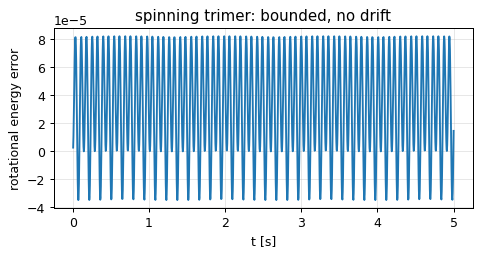

In [12]:
s = sim3d.make_sim(QUIET, "graphite", [R] * 3, c0 + np.array([[-2 * R, 0, 0], [0, 0, 0], [2 * R, 0, 0]]), np.zeros((3, 3)))
b = cl.merge(s.clumps, cl.merge(s.clumps, 0, 1), 2)
c = s.clumps
c.L[b] = np.linalg.inv(c.Iinv[b]) @ (2 * math.pi * 5 * np.array([math.cos(0.65), math.sin(0.65), 0.0]))
E0, L0 = 0.5 * c.L[b] @ c.Iinv[b] @ c.L[b], c.L[b].copy()
dE = []
for _ in range(1250):                                     # 5 s
    sim3d.step(s); dE.append(0.5 * c.L[b] @ c.Iinv[b] @ c.L[b] / E0 - 1)
print(f"trimer, 5 s: |dL|/L = {np.linalg.norm(c.L[b] - L0) / np.linalg.norm(L0):.1e}, max |dE/E| = {np.abs(dE).max():.1e}")

def precession_error(h, T=0.2):
    s = sim3d.make_sim(QUIET, "silica", [R, R], [c0 - [R, 0, 0], c0 + [R, 0, 0]], np.zeros((2, 3)))
    b = cl.merge(s.clumps, 0, 1); c = s.clumps
    I_perp = 2 * (c.I0[0] + c.m[0] * R * R)
    c.L[b] = np.array([0.3, 0.0, 1.0]) * I_perp * 2 * math.pi * 3
    e0 = (c.pos[1] - c.pos[0]) / (2 * R)
    for _ in range(int(round(T / h))):
        cl.rotate(c, np.array([b]), h)
    c.pos = c.X[c.body] + c.off
    k, th = c.L[b] / np.linalg.norm(c.L[b]), np.linalg.norm(c.L[b]) / I_perp * T
    Kx = impacts.skew(k)
    exact = (np.eye(3) + math.sin(th) * Kx + (1 - math.cos(th)) * Kx @ Kx) @ e0   # e0 turned about L by th
    return np.linalg.norm((c.pos[1] - c.pos[0]) / (2 * R) - exact)
errs = [precession_error(h) for h in (4e-3, 2e-3, 1e-3)]
print("dimer axis error after 0.2 s at h = 4, 2, 1 ms:", [f"{x:.1e}" for x in errs],
      " ratios:", [f"{errs[i] / errs[i + 1]:.2f}" for i in range(2)], "(4 = second order)")
plt.figure(figsize=(6, 2.6)); plt.plot(np.arange(1, 1251) * 4e-3, dE)
plt.xlabel("t [s]"); plt.ylabel("rotational energy error"); plt.title("spinning trimer: bounded, no drift"); plt.show()

## 7. Clumps breaking: erosion and shattering

After a bounce, a free clump of $N$ grains held by $N_c = N - 1$ bonds can lose grains. With the translational
energy of the impact $E_{coll} = \frac12\mu_{AB}|\mathbf V_A - \mathbf V_B|^2$ ($\mu_{AB}$ the reduced mass of the
two clumps) and the energy to break one bond $E_{break} = 1.54\,F_c|\delta_c|$ (Chokshi, Tielens & Hollenbach 1993):
above $3N_cE_{break}$ the struck grain is knocked off (erosion), above $10N_cE_{break}$ the clump shatters into single
grains (Dominik & Tielens 1997). (v0.5 `_fragment`.) Those thresholds were derived for large aggregates, in which
rolling a grain over its neighbour is easy; here they are **extrapolated** to clumps of 2-3 grains, for which the
rolling energy is 25× (graphite) to 61× (silica) $E_{break}$, the opposite regime.

*The bonds.* Each clump stores its bonds, the grain pairs that stuck (`Clumps.bonds`). Erosion pays for the bonds
the struck grain really has, and a clump splits only where its bonds are cut. They are stored, not recomputed
from distances, because a grain that sticks to a **spinning** clump is merged where the straight-line search of
section 3 put it, up to $1.25\times10^{-3}\rho$ (a few nm here) from touching: in the graphite run of section 8,
the trimers have bonds with gaps of 0.1-2 nm, which a tight distance test (1e-6 of the radius sum) would not see.

*The energy budget.* Rigid bodies have only one source for the broken bonds: $E_{diss}$, the kinetic energy the
bounce removed (section 4.3). If it cannot pay for a shatter, the clump erodes; if it cannot pay for that, nothing
breaks. *What happens to the rest, $E_{diss} - \text{cost}$, is not known* (**ASSUMED**). The 1-D contact model turned
it into heat (damping, adhesion hysteresis, yield). The full simulator's v0.5 engine gives ALL of it back as the
kinetic energy with which the fragments fly apart, and so does the core by default (`Tubule.separation = 1`):
velocity kicks $s\,\mathbf u_p$ radial from the old centre of mass, with $\sum M_p\mathbf u_p = 0$ (momentum
kept) and no angular momentum about the common centre of mass, $s$ chosen so the kinetic energy rises by exactly
separation × ($E_{diss}$ − cost). Either way kinetic plus broken-bond energy never rises (the tests check 90 random
impacts). How much it matters: in the two-tubule run of section 8, the three break-ups give back 1.1 to 6.2
$E_{break}$ (up to 1e-13 J), which changes the fragments' speeds by 3 to 10 mm/s, above silica's 6.7 mm/s
wall-sticking speed. The opposite bound, `separation = 0` (it all stays heat; the fragments keep the rigid-body
velocities they had at the break, so they never overlap), is run in section 9.

In [13]:
for v in (0.011, 0.06):                                    # a grain onto one end of a silica dimer
    s = sim3d.make_sim(sim3d.Tubule(accel=(0, 0, 0), mu=0.3), "silica", [R] * 3,
                       [c0 - [R, 0, 0], c0 + [R, 0, 0], c0 + [-R, 5 * R, 0]], [[0, 0, 0], [0, 0, 0], [0, -v, 0]])
    cl.merge(s.clumps, 0, 1)
    sim3d.run(s, 0.05, stop_when_settled=False)
    e = s.events[0]
    E_b = impacts.break_energy(dc.make_pair("silica", R, "silica", R))
    print(f"{v*1e3:4.0f} mm/s: {e['outcome']}, E_coll = {e['E_coll'] / E_b:5.1f} E_break, E_diss = "
          f"{e['E_diss'] / E_b:4.1f} E_break -> {e['mode'] or 'no break-up'}; clumps after: "
          f"{sorted(int(s.clumps.n[b]) for b in np.flatnonzero(s.clumps.alive))}")

  11 mm/s: bounce, E_coll =   6.7 E_break, E_diss =  3.2 E_break -> erosion; clumps after: [1, 1, 1]
  60 mm/s: bounce, E_coll = 199.1 E_break, E_diss = 53.6 E_break -> shatter; clumps after: [1, 1, 1]


## 8. Two tubules: silica and graphite from the same start

Two identical tubules side by side in microgravity; one holds silica grains, the other graphite grains. Everything
else is the SAME: the grain sizes, positions, velocities and adhesion factors (`scenes.two_tubule_start`):

In [14]:
for k, v in scenes.START_SOURCES.items():
    print(f"- {k}: {v}")

- tubule: 0.5 x 0.5 x 1.5 in inner, borosilicate, standing (long axis z = rocket axis), wall adhesion factor 1.0: configs/mission_quarter_deck.json (T1, T2)
- materials: silica in one tubule, graphite in the other; values from dolle_core/materials.py
- n_grains: 100 per tubule: the value of the full simulator's flight campaign; DOLL-E's dust amount is not decided
- sizes: diameters from the 90-106 um sieve range with 90 % inside, log-normal centred on the band (the log-normal shape is ASSUMED, as in dolle_sim/sizes.py); the SAME sample in both tubules
- adhesion_scatter: factor exp(0.6 N(0,1)) per grain on the work of adhesion; pairs sqrt(f_i f_j), wall f_i: configs/mission_quarter_deck.json surface_energy_log_sigma, from the ~70 % scatter of AFM adhesion on clean glass (Rush et al. 2018, PROVENANCE.md)
- positions: ASSUMED: a compact released cloud, uniform in a 2 mm cube at the tubule centre, centres at least 1.06 x the sum of radii apart (the full simulator's spacing rule)
- velocit

> **Why this choice: a compact cloud as the start (ASSUMED).** 100 grains of 100 µm spread through the whole tubule
> practically never meet: the mean free path $1/(n\pi(2r)^2)$ is about 2 m, while the walls are about 6 mm away,
> so the walls catch every grain first (the cell at the end of this section runs it). Clumps form only if the dust
> starts as a compact cloud, or with many more grains (the number of impacts grows as $N^2$). How DOLL-E releases
> its dust is not decided. 15 mm/s is chosen between the two sticking speeds (6.2 mm/s for silica, 38 mm/s for
> graphite; notebook 03) so that the same start is fast for silica and slow for graphite.

In [15]:
start = scenes.two_tubule_start()                       # n = 100, seed 7, 2 mm cube, |N(15, 7.5)| mm/s
sims = scenes.run_two_tubules(start, t_end=12.0)        # a few seconds
for mat, s in sims.items():
    sm, cnt = sim3d.summary(s), s.counts
    print(f"{mat:9s}: {sm['grain_grain_impacts']} grain-grain impacts ({cnt['stick']} stick, {cnt['bounce']} bounce; "
          f"{cnt['erosion']} erosion, {cnt['shatter']} shatter), last at {sm['last_grain_grain_impact_s']:.2f} s; "
          f"wall: {cnt['wall_stick']} captures, {cnt['wall_bounce']} bounces")
    print(f"{'':9s}  clumps at the end (size: number): {sm['clump_sizes_at_end']}; free at the end: "
          f"{sm['free_clumps_at_end']} (t = {sm['t_end_s']:.2f} s); computed in {sm['run_time_s']:.1f} s")
    print(f"{'':9s}  momentum: worst event dP_rel = {sm['max_event_dP_rel']:.1e}, dL_rel = {sm['max_event_dL_rel']:.1e}; "
          f"whole-run ledger {sm['ledger_dP_rel']:.1e}, {sm['ledger_dL_rel']:.1e}")
    print(f"{'':9s}  first grain-grain impact times [s]:", [round(e["t"], 3) for e in s.events if e["kind"] == "pp"][:8])
    pp = [e for e in s.events if e["kind"] == "pp"]
    print(f"{'':9s}  grain-grain normal speeds: median {np.median([e['v_n'] for e in pp]) * 1e3:.1f} mm/s; "
          f"fastest stick {max(e['v_n'] for e in pp if e['outcome'] == 'stick') * 1e3:.2f} mm/s")
    for e in s.events:
        if e["mode"]:
            how = "hit by a grain" if e["kind"] == "pp" else "bouncing off a wall"
            print(f"{'':9s}  {e['mode']} at t = {e['t']:.3f} s: a clump of {max(e['n_i'], e['n_j'])} {how} "
                  f"at {e['v_n'] * 1e3:.1f} mm/s")

silica   : 20 grain-grain impacts (4 stick, 16 bounce; 0 erosion, 2 shatter), last at 0.09 s; wall: 95 captures, 138 bounces
           clumps at the end (size: number): {'1': 96, '2': 2}; free at the end: 3 (t = 12.00 s); computed in 4.0 s
           momentum: worst event dP_rel = 2.4e-16, dL_rel = 7.1e-16; whole-run ledger 1.8e-14, 9.5e-15
           first grain-grain impact times [s]: [0.006, 0.011, 0.012, 0.012, 0.014, 0.018, 0.018, 0.026]
           grain-grain normal speeds: median 11.6 mm/s; fastest stick 5.08 mm/s
           shatter at t = 0.075 s: a clump of 2 hit by a grain at 10.2 mm/s
           shatter at t = 0.465 s: a clump of 2 bouncing off a wall at 14.3 mm/s
graphite : 17 grain-grain impacts (17 stick, 0 bounce; 1 erosion, 0 shatter), last at 0.50 s; wall: 84 captures, 19 bounces
           clumps at the end (size: number): {'1': 72, '2': 8, '3': 4}; free at the end: 0 (t = 3.94 s); computed in 2.1 s
           momentum: worst event dP_rel = 2.1e-16, dL_rel = 1.2e-15;

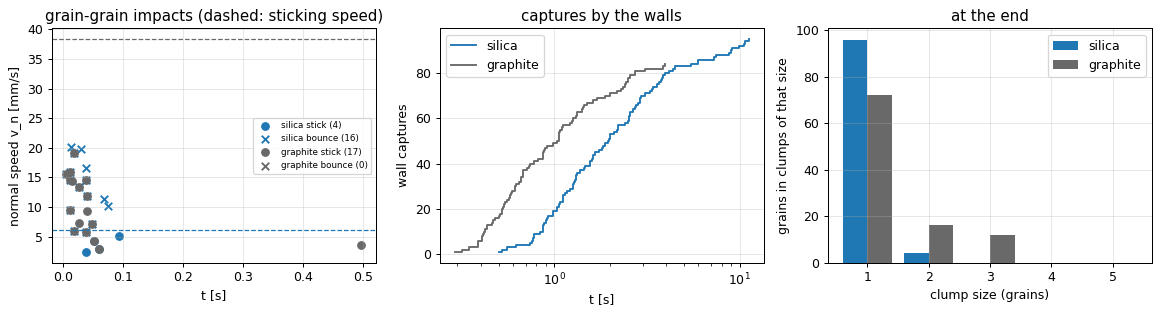

In [16]:
th = {m: scenes.thresholds(m) for m in sims}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for k, (mat, s) in enumerate(sims.items()):
    pp = [e for e in s.events if e["kind"] == "pp"]
    col = "tab:blue" if mat == "silica" else "dimgray"
    for out, mk in (("stick", "o"), ("bounce", "x")):
        vs = [e["v_n"] * 1e3 for e in pp if e["outcome"] == out]
        ts = [e["t"] for e in pp if e["outcome"] == out]
        ax[0].scatter(ts, vs, marker=mk, color=col, label=f"{mat} {out} ({len(vs)})")
    ax[0].axhline(th[mat]["grain_grain"] * 1e3, color=col, ls="--", lw=1)
    walls = sorted(e["t"] for e in s.events if e["kind"] == "wall" and e["outcome"] == "stick")
    ax[1].step(walls, np.arange(1, len(walls) + 1), where="post", color=col, label=mat)
    sizes = [int(s.clumps.n[b]) for b in np.flatnonzero(s.clumps.alive)]
    ax[2].bar(np.arange(1, 6) + (0.2 if k else -0.2), [sizes.count(n) * n for n in range(1, 6)], width=0.4,
              color=col, label=mat)
ax[0].set(xlabel="t [s]", ylabel="normal speed v_n [mm/s]", title="grain-grain impacts (dashed: sticking speed)")
ax[0].legend(fontsize=7)
ax[1].set(xlabel="t [s]", ylabel="wall captures", title="captures by the walls", xscale="log"); ax[1].legend()
ax[2].set(xlabel="clump size (grains)", ylabel="grains in clumps of that size", title="at the end"); ax[2].legend()
plt.tight_layout(); plt.show()

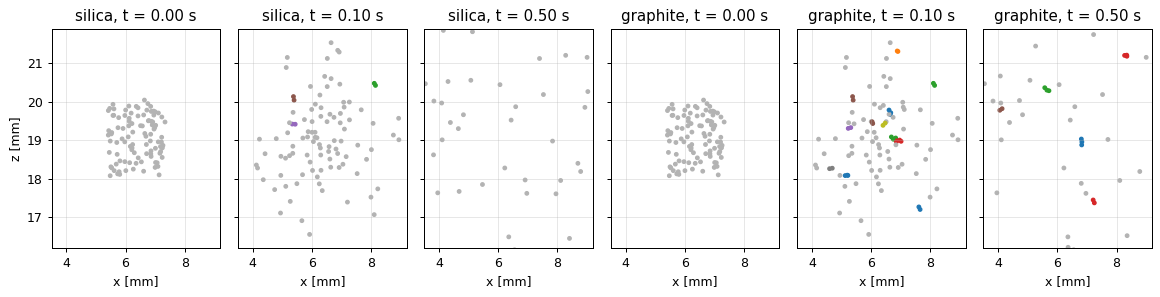

In [17]:
# Side view (x across, z along the tubule) of both clouds at three moments; colour = clump (grey: single grains).
fig, ax = plt.subplots(1, 6, figsize=(13, 3.4), sharey=True)
for k, (mat, s) in enumerate(sims.items()):
    for j, t_show in enumerate((0.0, 0.1, 0.5)):
        f = min(s.frames, key=lambda f: abs(f["t"] - t_show))
        p, n_of = f["pos_um"] / 1e3, np.bincount(f["clump"], minlength=len(f["clump"]))[f["clump"]]
        a = ax[3 * k + j]
        colours = [plt.cm.tab10(k % 10) if n > 1 else (0.7, 0.7, 0.7, 1.0) for k, n in zip(f["clump"], n_of)]
        a.scatter(p[:, 0], p[:, 2], s=8, c=colours)
        a.set(xlim=(3.5, 9.2), ylim=(16.2, 21.9), title=f"{mat}, t = {f['t']:.2f} s", xlabel="x [mm]")
ax[0].set_ylabel("z [mm]"); plt.tight_layout(); plt.show()

**Why this happens.** The two tubules start identically, and their grains meet each other equally often at first:
the first impacts are the same pairs at the same speeds in both tubules (compare the two lists of times), about 20
impacts each, all in the first half second, at median normal speeds of about 12 mm/s (silica) and 10 mm/s (graphite), printed above. The difference is what
happens at each impact. Silica's grain-grain sticking speed is 6.2 mm/s (lower for grains with a low adhesion
factor), so most silica impacts bounce; the 4 that stick are all at or below 5.1 mm/s, and 2 of the 4 dimers are
shattered again (one by a grain at 10 mm/s, one when it bounces off a wall at 14 mm/s). Graphite's sticking speed is
38 mm/s, above every impact here, so every graphite impact sticks, also onto dimers: dimers and trimers form, and
only one dimer loses a grain (erosion, when it bounces off a wall at 22 mm/s). **Graphite clumps far more: about 28
of its 100 grains end in clumps, against 4 for silica.** After the first half second the cloud has spread out and
the walls catch the grains: graphite almost at once (it sticks to borosilicate below 18 mm/s), silica after
bouncing a few times (below 6.7 mm/s), so a few silica grains with low adhesion factors are still bouncing at 12 s.
The momentum checks are at round-off: ~$10^{-16}$ per event, ~$10^{-14}$ for the whole run (the sum of thousands of
round-offs).

The same grains spread through the whole tubule instead:

In [18]:
size, rad = np.asarray(start["tubule"].size), start["radii"]
spread = {**start, "positions": scenes.puff_positions(rad, size / 2, size - 4 * rad.max(), np.random.default_rng(1007))}
for mat in ("silica", "graphite"):
    s = scenes.run_tubule(spread, mat, 12.0, frame_dt=1.0, slow_until=0.0)
    sm = sim3d.summary(s)
    print(f"{mat:9s} spread through the tubule: {sm['grain_grain_impacts']} grain-grain impacts, largest clump "
          f"{sm['largest_clump']}; {sm['free_clumps_at_end']} grains still free at t = {s.t:.1f} s")

silica    spread through the tubule: 1 grain-grain impacts, largest clump 1; 3 grains still free at t = 12.0 s


graphite  spread through the tubule: 0 grain-grain impacts, largest clump 1; 0 grains still free at t = 6.9 s


## 9. What the rigid-clump simulation leaves out, and how much it matters

The 3-D core keeps the contact physics of the full simulator (the same materials, pair rules, JKR contact, damping,
yield, friction table, fragmentation energies) and the same event-driven method as its v0.5 chamber engine. It
leaves out:

| left out | its size in the two-tubule scenario | how it is checked |
|---|---|---|
| gas drag (1e-3 Pa in the payload) | drag time $m/c$ ≈ 1.3-1.5 × 10⁴ s: speeds change by < 0.1 % in 12 s | v0.5 with and without, 6 seeds × 100 grains: grain-grain impacts / sticks unchanged (silica 97/21, graphite 87/82)¹ |
| the payload's slow roll (1 rpm residual) | centrifugal $\Omega^2 r$ ≈ 1.0 × 10⁻³ m/s² at the tubule's deck radius, similar to the residual; Coriolis $2\Omega v$ turns velocities at 0.21 rad/s, 0.03 rad over the 0.15 s cloud phase, without changing speeds. It moves where grains land, not how they collide | v0.5 with and without, 6 seeds × 100 grains: within 2σ (Poisson) only: silica 97/21 → 96/27, graphite 87/82 → 91/86¹. Checked only to that level; whether v0.5's Coriolis kick should be added to the core is OPEN |
| contact charging and electric forces | in the simulator's model charge is driven by work-function differences: silica (5.0 eV) on borosilicate (5.0 eV) does not charge; graphite (4.6 eV) charges on the walls to about the 0.4 V difference, and two such grains at contact repel with ~10⁻³ of the impact energy at graphite's sticking speed (computed below) | v0.5 with charging, Coulomb, polarisation and image forces, 6 seeds × 100 grains: unchanged (silica 97/21, graphite 87/82)¹ |
| g-jitter | uniform: it changes no relative velocity | none needed |
| wall vibration, release shaking, grains pulled off walls | the scenario starts after the release, in microgravity; pull-off needs ≳ 100 g against 10⁻⁴ g (notebook 04) | none needed |
| the resting-contact rule of v0.5 | acts only if $a_n\Delta t$ exceeds the rebound speed: $a_n\Delta t$ = 4 µm/s here | none needed |
| negligible forces (gravity gradient, grain-grain gravity, Lorentz force, photophoresis, radiation pressure, Brownian motion) | switched off by default in the full simulator too; sizes in PROVENANCE.md | none needed |
| restructuring inside clumps (rolling) | impacts carry 0.03 (silica) / 0.005 (graphite) of the onset energy, but the rolling resistance is uncertain ~50× | OPEN (section 5) |
| impacts lasting a finite time | ~1 µs; a third grain arrives during one with chance ~6 × 10⁻⁶ | v0.5 does the same |
| the separation energy after a break-up (ASSUMED, section 7) | all of $E_{diss}$ − cost given back (v0.5 and the core's default) against none | both engines with none: the core's two tubules (below), silica 20 impacts / 4 sticks → 22 / 6, graphite 17 / 17 → 18 / 18; v0.5, 6 seeds × 100 grains: silica 97/21 → 98/22, graphite 87/82 → 88/83² |
| the fragmentation thresholds (Dominik & Tielens 1997) | derived for large aggregates; EXTRAPOLATED to 2-3 grain clumps (section 7) | none possible here: only 3 break-ups in the two-tubule run |

And it differs from v0.5 on purpose in four places, each checked against v0.5 (tests/test_dolle_core_sim3d.py):
candidate pairs by a brute-force distance test (no k-d tree); one event at a time; **exact** radii and adhesion in
every contact law (v0.5 rounds radii to 0.5 µm and the adhesion factor to 2 % in its cache, an $R^*$ error up to
0.5 %); and per-pair friction from the sourced table (v0.5 used one value, 0.3; `Tubule(mu=0.3)` reproduces it). The
cell below computes the sizes of the table, then runs the full simulator's v0.5 engine on the same 30-grain start
as the core (radii on its 0.5 µm grid, $\mu$ = 0.3): the events must be the same.

¹ grain-grain impacts / sticks summed over 6 seeds of 100 grains, 0.6 s, off → on;
`tests/test_dolle_core_sim3d.py::test_left_out_effects_do_not_change_grain_grain_outcomes` runs these and requires
every change to stay within 2σ (Poisson).
² the same runs with `"contact": {"fragment_separation": 0}`; `tests/test_dolle_core_sim3d.py::test_separation_bound_in_both_engines` runs them.

In [19]:
G0, m50 = dc.G0, dc.sphere_mass(2000.0, R)
Om = 2 * math.pi * 0.0167                                 # 1 rpm residual roll (configs/mission_quarter_deck.json)
print(f"roll: centrifugal {Om**2 * math.hypot(0.080, 0.050):.2e} m/s^2 (residual {1e-4 * G0:.2e}); "
      f"Coriolis turn rate {2 * Om:.2f} rad/s -> {2 * Om * 0.15:.3f} rad in 0.15 s")
n_cloud = 100 / (2e-3) ** 3
print(f"chance of a third grain during a 1 us contact: {n_cloud * math.pi * (2 * R) ** 2 * 0.015 * 1e-6:.1e}")
print(f"resting rule a_n dt = {1e-4 * G0 * 4e-3 * 1e6:.1f} um/s")
q = 4 * math.pi * 8.8541878128e-12 * R * 0.4             # graphite grain charged to the 0.4 V work-function difference
p_gr = dc.make_pair("graphite", R, "graphite", R)
v_star = dc.sticking_threshold(p_gr)
print(f"graphite charge q = {q:.1e} C; Coulomb energy at contact k q^2/(2r) = {8.9875517923e9 * q * q / (2 * R):.1e} J "
      f"against 1/2 m* v*^2 = {0.5 * p_gr.m_star * v_star ** 2:.1e} J")
try:                                                      # the full simulator's gas drag and work functions
    from dolle_sim.environment import Environment
    from dolle_sim.materials import get_material
    env = Environment({"preset": "ideal", "pressure_pa": 1e-3, "gas": "air", "temperature_k": 293.0},
                      np.random.default_rng(0))
    for mat in ("silica", "graphite"):
        tau = dc.make_pair(mat, R, mat, R).m1 / float(env.drag_coeff(np.array([R]))[0])
        print(f"{mat:9s}: drag time m/c at 1e-3 Pa = {tau:.2e} s; work function {get_material(mat).work_function} eV "
              f"(borosilicate {get_material('glass_borosilicate').work_function} eV)")
except ImportError as err:
    print("dolle_sim is not importable here:", err)
from dataclasses import replace                           # the separation bound (section 7): none given back
for sep in (1.0, 0.0):
    st = {**start, "tubule": replace(start["tubule"], separation=sep)}
    for mat in ("silica", "graphite"):
        s = scenes.run_tubule(st, mat, 12.0)
        sm = sim3d.summary(s)
        print(f"separation = {sep:g}, {mat:9s}: {sm['grain_grain_impacts']} grain-grain impacts, "
              f"{s.counts['stick']} sticks, {s.counts['erosion'] + s.counts['shatter']} break-up(s); "
              f"clumps at the end {sm['clump_sizes_at_end']}")

roll: centrifugal 1.04e-03 m/s^2 (residual 9.81e-04); Coriolis turn rate 0.21 rad/s -> 0.031 rad in 0.15 s
chance of a third grain during a 1 us contact: 5.9e-06
resting rule a_n dt = 3.9 um/s
graphite charge q = 2.2e-15 C; Coulomb energy at contact k q^2/(2r) = 4.5e-16 J against 1/2 m* v*^2 = 4.2e-13 J
silica   : drag time m/c at 1e-3 Pa = 1.34e+04 s; work function 5.0 eV (borosilicate 5.0 eV)
graphite : drag time m/c at 1e-3 Pa = 1.47e+04 s; work function 4.6 eV (borosilicate 5.0 eV)


separation = 1, silica   : 20 grain-grain impacts, 4 sticks, 2 break-up(s); clumps at the end {'1': 96, '2': 2}


separation = 1, graphite : 17 grain-grain impacts, 17 sticks, 1 break-up(s); clumps at the end {'1': 72, '2': 8, '3': 4}


separation = 0, silica   : 22 grain-grain impacts, 6 sticks, 2 break-up(s); clumps at the end {'1': 92, '2': 4}


separation = 0, graphite : 18 grain-grain impacts, 18 sticks, 1 break-up(s); clumps at the end {'1': 70, '2': 9, '3': 4}


In [20]:
def v05_events(tub, mats, radii, pos, vel, t_end):
    # the full simulator's v0.5 chamber engine on the core's start (one particle group per grain, then overwritten)
    from dolle_sim.simulation import ChamberSim
    off = ("coulomb", "polarization", "image_charges", "self_gravity", "lorentz", "external_e_field",
           "thermophoresis", "photophoresis", "radiation_pressure", "brownian", "space_charge")
    cfg = {"dt_s": tub.dt, "duration_s": t_end,
           "environment": {"preset": "ideal", "pressure_pa": 0.0, "residual_accel_g": [a / G0 for a in tub.accel],
                           "gravity_gradient": False},
           "forces": {k: False for k in off}, "contact": {"friction_coefficient": tub.mu, "contact_charging": False}}
    groups = [{"material": m, "count": 1, "radius_m": float(r), "velocity": {"speed_mean_m_s": 0.0}}
              for m, r in zip(mats, radii)]
    s = ChamberSim(cfg, {"name": "x", "size_m": list(tub.size), "wall_material": tub.wall, "particles": groups}, 0)
    s.pos, s.V = np.array(pos), np.array(vel)
    s.X = s.pos.copy()
    s.run(progress=False)
    return s.collisions

rng = np.random.default_rng(3)
tub = sim3d.Tubule(mu=0.3)
r = np.round(scenes.sieve_radii(30, rng=rng) * 2e6) / 2e6          # on v0.5's 0.5 um grid
pos = scenes.puff_positions(r, size / 2, 1.5e-3, rng)
vel = scenes.isotropic_velocities(30, 0.015, 0.0075, rng)
try:
    for mat in ("silica", "graphite"):
        core = sim3d.run(sim3d.make_sim(tub, mat, r, pos, vel), 3.0, stop_when_settled=False).events
        ref = v05_events(tub, [mat] * 30, r, pos, vel, 3.0)
        same = sum(1 for x, y in zip(core, ref) if (x["kind"], x["i"], x["j"], x["outcome"]) ==
                   (y["kind"], y["i"], y["j"], y["outcome"]) and abs(x["t"] - y["t"]) < 1e-9)
        dt = max(abs(x["t"] - y["t"]) for x, y in zip(core, ref))
        dv = max(abs(x["v_n"] - y["v_n"]) / y["v_n"] for x, y in zip(core, ref))
        print(f"{mat:9s}: core {len(core)} events, v0.5 {len(ref)}; identical: {same}; "
              f"largest time difference {dt:.1e} s, speed difference {dv:.1e}")
except ImportError as err:
    print("the full simulator's v0.5 engine is not importable here:", err)

silica   : core 69 events, v0.5 69; identical: 69; largest time difference 7.1e-14 s, speed difference 1.1e-13


graphite : core 34 events, v0.5 34; identical: 34; largest time difference 1.3e-15 s, speed difference 2.4e-15


## 10. The data of the web page

The page `docs/sim3d/` shows the two tubules, one impact up close, and a small live sandbox.

- **Recorded replays:** `python tools/make_sim3d_replays.py` (about 10 s) runs section 8 and writes
  `docs/sim3d/data/two_tubules.json` (frames every 4 ms up to 0.5 s, then 30 per second; positions in integer µm;
  every event with its conservation errors; the summaries) and `docs/sim3d/data/impact_closeup.json` (two 50 µm
  radius grains head-on at 0.8 and 1.5 times the sticking speed, per material: the force, overlap, patch radius,
  velocities and energies of every sub-step, from `dc.impact(..., record=True)`).
- **Live sandbox:** the page loads these same python files into the browser (Pyodide) and calls
  `scenes.sandbox_start(params_json)` (the page's choices, including the sieve cut `d_min_um`, `d_max_um`) and
  `scenes.sandbox_advance(state, seconds)`, which exchange JSON text: new frames, events, counts and, per frame,
  one row of the momentum ledger (`scenes.MomentumRecorder`; columns `scenes.MOMENTUM_COLUMNS`) for the page's
  momentum plot. The frame clock is kept in the `Sim`, so the pieces join with an even frame spacing, and the
  last frame is at the end of the chosen duration:

In [21]:
import json
state = scenes.sandbox_start(json.dumps({"n": 30, "seed": 2, "box_mm": 1.2}))
t0 = time.perf_counter()
out = json.loads(scenes.sandbox_advance(state, 0.5))
print(f"0.5 s of two 30-grain tubules in {time.perf_counter() - t0:.2f} s of computer time")
for t in out["tubules"]:
    print(f"  {t['material']:9s}: {len(t['frames']['t'])} frames, {len(t['events'])} events, counts {t['counts']}")
print("event columns:", out["event_columns"])

0.5 s of two 30-grain tubules in 0.58 s of computer time
  silica   : 126 frames, 16 events, counts {'stick': 0, 'bounce': 5, 'wall_stick': 0, 'wall_bounce': 11, 'erosion': 0, 'shatter': 0, 'guard': 0, 'fragmentation_energy_limited': 0}
  graphite : 126 frames, 14 events, counts {'stick': 4, 'bounce': 0, 'wall_stick': 6, 'wall_bounce': 4, 'erosion': 0, 'shatter': 0, 'guard': 0, 'fragmentation_energy_limited': 0}
event columns: ['t_s', 'kind', 'i', 'j', 'outcome', 'v_n_mm_s', 'v_t_mm_s', 'e_n', 'n_i', 'n_j', 'x_um', 'y_um', 'z_um', 'fragments', 'mode', 'dP_rel', 'dL_rel']


## What to remember

- The 3-D core moves clumps in straight lines between impacts and finds the **exact** moment of each contact from a
  quadratic equation; spinning clumps take shorter drifts so their arcs are followed to within
  $\rho\theta^2/2 = 1.25\times10^{-3}\rho$ ($\rho$: a member's distance from the centre of mass).
- Every impact is decided by the **1-D contact model** of notebook 01 with the **effective mass**
  $m_{eff} = 1/(\mathbf n\cdot K\mathbf n)$ at the contact point; head-on it reproduces the 1-D answer exactly, and
  oblique impacts stick at the same normal speed in the full 3-D contact model.
- Stuck grains become **rigid clumps**; merging, bouncing (+P and −P at one point) and breaking up conserve momentum
  and angular momentum by algebraic identities, so the errors are round-off (~$10^{-16}$ per event).
- From the same compact start, **graphite clumps far more than silica**: its sticking speed (38 mm/s) is above
  almost every impact, silica's (6.2 mm/s) below most. Spread through the tubule, almost no grains meet.
- Left out: gas drag and charging (checked in the full simulator: no change in the grain-grain outcomes), the slow
  roll (checked only to within 2σ: silica sticks 21 → 27), restructuring inside clumps (OPEN), and the negligible
  forces. ASSUMED: the energy fragments fly apart with after a break-up (the opposite bound changes silica's sticks
  from 4 to 6 in the two-tubule run) and the fragmentation thresholds for 2-3 grain clumps.

## Check it yourself

1. Halve the start speed (`scenes.two_tubule_start(speed_mm_s=7.5, sigma_mm_s=3.75)`) and run both tubules. Predict
   first: does silica now clump? Which impacts still bounce, and why?
2. Make the cloud 4 mm instead of 2 mm (`box_mm=4.0`). The density drops 8×: by how much should the number of
   grain-grain impacts drop? Check it.

In [22]:
# your turn, e.g.:
# slow = scenes.run_two_tubules(scenes.two_tubule_start(speed_mm_s=7.5, sigma_mm_s=3.75))
# print({m: sim3d.summary(s)["clump_sizes_at_end"] for m, s in slow.items()})